In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("data/synthetic_daily_data.csv", parse_dates=["date"])
df.head()

,date,day_of_week,week,low_demand_day,off_task,demand_refusal,elopement,unsafe_physical,points_possible,points_earned,g10_opps,g10_correct,g11_opps,g11_correct,g12_opps,g12_correct,narrative_note
0,2025-09-02,Tuesday,1,No,10,6,1,1,20,8,4,1,8,2,5,2,Typical day. Off-task behavior was frequent; r...
1,2025-09-03,Wednesday,1,No,17,5,3,2,20,9,6,2,8,4,7,2,Participated briefly with the group before req...
2,2025-09-04,Thursday,1,No,16,5,2,2,20,11,6,2,4,1,8,2,Typical day. Off-task behavior was frequent; r...
3,2025-09-05,Friday,1,No,15,8,3,1,20,7,5,3,8,3,8,3,Verbal refusal during math. Chose a movement b...
4,2025-09-08,Monday,1,Yes,7,4,1,0,20,13,7,3,8,5,7,3,Low demand day. Mostly engaged in preferred ac...


,off_task,demand_refusal,elopement,unsafe_physical
low_demand_day,,,,
No,15.0,6.8,3.1,1.5
Yes,4.1,2.8,0.9,1.0


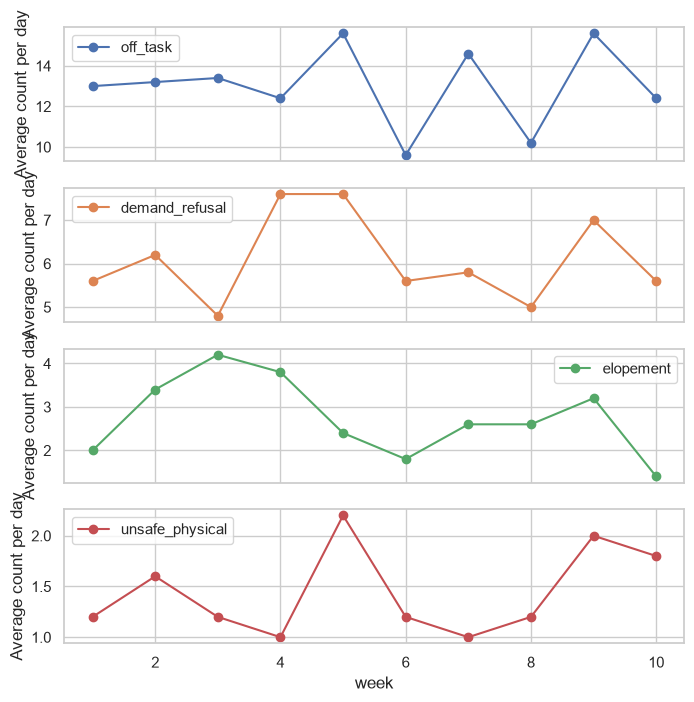

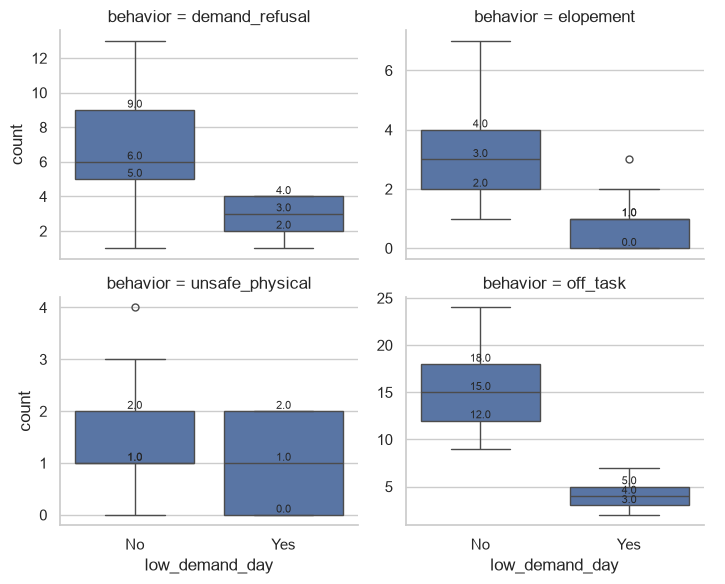

In [3]:
from matplotlib import axes


df["day_num"] = (df["date"] - df["date"].min()).dt.days

df_long = df.melt(id_vars=["day_num", "low_demand_day"], value_vars=["demand_refusal", "elopement", "unsafe_physical", "off_task"], var_name="behavior", value_name="count")

behaviors = ["off_task", "demand_refusal", "elopement", "unsafe_physical"]

# weekly averages over time
weekly = df.groupby("week")[behaviors].mean()
weekly.plot(subplots=True, sharey=False, marker="o", figsize=(8, 8),
            ylabel="Average count per day")


# behavior count by low demand day
display(df.groupby("low_demand_day")[behaviors].mean().round(1))
plot = sns.catplot(data=df_long, x="low_demand_day", y="count",
            col="behavior", col_wrap=2, kind="box",
            sharey=False, height=3, aspect=1.2)

# quartile statistics for low demand day
stats = (df_long.groupby(["behavior", "low_demand_day"])["count"]
         .quantile([0.25, 0.5, 0.75]).unstack())

# label quartiles function
def add_label(ax, behavior, low_demand_day, x):
    q1 = stats.loc[(behavior, low_demand_day), 0.25]
    q2 = stats.loc[(behavior, low_demand_day), 0.5]
    q3 = stats.loc[(behavior, low_demand_day), 0.75]
    ax.text(x, q1, f"{q1:.1f}", ha="center", va="bottom", fontsize=8)
    ax.text(x, q2, f"{q2:.1f}", ha="center", va="bottom", fontsize=8)
    ax.text(x, q3, f"{q3:.1f}", ha="center", va="bottom", fontsize=8)

for behavior in behaviors:
    ax = plot.axes_dict[behavior]
    add_label(ax, behavior, "No", 0)
    add_label(ax, behavior, "Yes", 1)


The data was sorted in three different ways for exploratory visualization. The line plot shows a weekly aggregate per behavior to show trends in each behavior over time. Unsafe physical behavior, demand refusal and off-task behaviors peak around week 5. 

The boxplot chart plots behaviors grouped by days where behavioral demand was low (such as "Friday Fun" days, with little to no school work demands) and where demand was not low, or average. The medians are higher on non-low demand days and do not overlap with low demand days for demand refusal, elopment and off task behavior. Off task behavior has the largest gap between demand day types, with a median of 15.0 instances on average days and a median of 4.0 on low demand days. Unsafe physical behavior has an equal median of 1.0 for both demand day types.

day_of_week
Monday       10
Tuesday      10
Wednesday    10
Thursday     10
Friday       10
Name: count, dtype: int64

,off_task,demand_refusal,elopement,unsafe_physical
day_of_week,,,,
Monday,14.7,6.9,2.9,1.4
Tuesday,12.4,5.0,2.3,1.2
Wednesday,11.2,6.2,2.0,1.6
Thursday,12.6,5.4,3.0,1.4
Friday,14.1,6.9,3.5,1.6
Overall,13.0,6.1,2.7,1.4


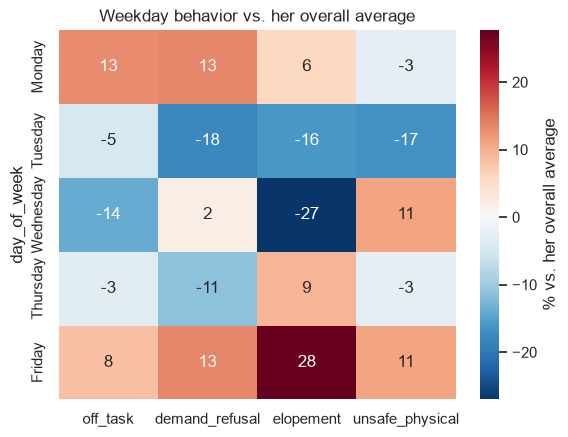

In [4]:
# behavior count sorted by day of week 
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
display(df["day_of_week"].value_counts().reindex(order))

#amount of days in each average: 10 days for each day of the week, 50 week days total
df["day_of_week"].value_counts()

# average behavior count by day of week
by_day = df.groupby("day_of_week")[behaviors].mean().reindex(order)
overall = df[behaviors].mean()

# heatmap of percent change from overall average by day of week
pct = (by_day - overall) / overall * 100
ax = sns.heatmap(pct, annot=True, fmt=".0f", cmap="RdBu_r", center=0,
                 cbar_kws={"label": "% vs. her overall average"})
ax.set_title("Weekday behavior vs. her overall average")


by_day.loc["Overall"] = overall.round(1)
display(by_day.round(1))



There are 50 week days total in this data set, with 10 days per day of the week (Monday through Friday), so the small sample per weekday should be noted. Boxes show percent difference from her average, with red being above average and blue being under her average for that behavior. Fridays have overall higher percentages of behavior (+8% on off task, +13% demand refusal, +28% elopement, +11% unsafe behavior), with elopement being the highest on Fridays (0.8 instances above average of 2.7 instances). Wednesdays have the biggest drop in elopement (0.7 instances below average of 2.7 instances). It should be noted that elopement has the largest percent differences compared to the average, but are only different by a raw count of less than 1 instance. Tuesdays are overall under the average for all behaviors.  

In [5]:
goals = ["g10", "g11", "g12"]

summary = pd.DataFrame({
    "opportunities": [df[g + "_opps"].sum() for g in goals],
    "correct": [df[g + "_correct"].sum() for g in goals],
}, index=goals)
summary["pct_correct"] = (summary["correct"] / summary["opportunities"] * 100).round(1)
display(summary)

,opportunities,correct,pct_correct
g10,247,104,42.1
g11,310,125,40.3
g12,321,189,58.9
